Importing all thwe libraries necessary for tekenization, cleaning, lemmatization, model training and evaluation


In [183]:
import pandas as pd
import re
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
import string
from collections import Counter
import seaborn as sns
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

Reading the dataset into a pandas dataframe and showing the shape, distribution, examples and null counts.

In [184]:
dataset = pd.read_csv("sentiment_dataset.csv")
print("First 10:\n", dataset.head(10), "\nShape: ", dataset.shape, "\nNull Count:\n", dataset.isnull().sum(), "\nDistribution:\n", dataset['sentiment'].value_counts())


First 10:
                                                 text sentiment
0               Seems okay so far. Will update later   neutral
1                 Average quality. Does what it says   neutral
2            Best  decision I made this month lol...  positive
3                  Excellent app, VERY user friendly  positive
4  Completely dissatisfied with everything Not re...  negative
5  cant believe how good this is for the price De...  positive
6  Highly recommend to anyone looking for #shoppi...  positive
7  The product arrived early and works great Supe...  positive
8                 Great features and easy navigation  positive
9  Product arrived broken and support wont help D...  negative 
Shape:  (600, 2) 
Null Count:
 text         0
sentiment    0
dtype: int64 
Distribution:
 sentiment
positive    270
negative    210
neutral     120
Name: count, dtype: int64


Preparing the text for processing by defining the regular expressions and the function that uses these to clean the text, lemmatize and remove the stopwords

In [185]:
HTML_TAG = re.compile(r"<.*?>")
URL = re.compile(r"https?://\S+|www\.\S+")
NUM_RE = re.compile(r"\d+")
ALPHABET_RE = re.compile(r"[^a-z\s]")
STOPWORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text: str) -> str:
    text = text.lower()
    text = HTML_TAG.sub(' ', text)
    text = URL.sub(' ', text)
    text = NUM_RE.sub(' ', text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = ALPHABET_RE.sub(' ', text)

    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]

    return ' '.join(tokens)

Applying the cleaning function on the dataset

In [186]:
dataset['cleaned_text'] = dataset["text"].apply(clean_text)

Displaying a sample of original and cleaned text side by side

In [187]:
display(dataset[['text', 'cleaned_text']].sample(10, random_state=42).rename(columns={'text': 'original_text'}))

,original_text,cleaned_text
110,Delivery was on schedule. Product is as described,delivery schedule product described
419,This exceeded all my expectations 😀 😀,exceeded expectation
565,"Gooood stuff, no issues at all",gooood stuff issue
77,Best purchase ever made. totally worth it,best purchase ever made totally worth
181,So happy I found this product,happy found product
284,love this app!! works perfectly 👍...,love app work perfectly
10,worst app ever. keeps crashing 😢,worst app ever keep crashing
469,Yeah this is totally worth the money 😞 NOT...,yeah totally worth money
78,Super fast shipping and great product quality...,super fast shipping great product quality grea...
349,10/10 would buy again https://tinyurl.com/abc,would buy


Displaying word and character counts for each record and the thewir averages

In [188]:
def word_count(input):
    return len(input.split()) if isinstance(input, str) else 0

def char_count(input):
    return len(input) if isinstance(input, str) else 0

dataset['word_count'] = dataset['cleaned_text'].apply(word_count)
dataset['char_count'] = dataset['cleaned_text'].apply(char_count)

print("Average Word Count: ", dataset["word_count"].mean())
print("Average Character Count: ", dataset["char_count"].mean())

Average Word Count:  4.22
Average Character Count:  28.326666666666668


Joining all the cleaned text into a single variable and counting the most common occurences accross them. Displays the most common words and characters by using display function on a dataframe

In [189]:
words = " ".join(dataset['cleaned_text']).split()
frequency = Counter(words)
top_words = frequency.most_common(50)
common_dataframe = pd.DataFrame(top_words, columns = ['word', "count"])
display(common_dataframe.head(10))

,word,count
0,product,104
1,app,85
2,work,85
3,quality,66
4,great,57
5,delivery,36
6,good,35
7,money,35
8,price,34
9,happy,33


Displaying the most common bigrams and trigrams usinbg Counter

In [190]:
def ngrams(tokens, n):
    return [" ".join(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

bigrams = Counter(ngrams(words, 2))
trigrams = Counter(ngrams(words, 3))

common_bi = pd.DataFrame(bigrams.most_common(20), columns=["word", "count"])
common_tri = pd.DataFrame(trigrams.most_common(20), columns=["word", "count"])

print("Common Bigrams:")
display(common_bi.head(20))
print("Common Trigrams:")
display(common_tri.head(20))



Common Bigrams:


,word,count
0,product arrived,23
1,great value,16
2,super happy,16
3,quality price,16
4,work perfectly,15
5,customer service,14
6,work great,13
7,waste money,13
8,doesnt work,13
9,highly recommend,12


Common Trigrams:


,word,count
0,dont waste money,11
1,app make life,11
2,make life easier,11
3,best decision made,10
4,decision made month,10
5,made month lol,10
6,product arrived broken,10
7,arrived broken support,10
8,broken support wont,10
9,support wont help,10


Displaying the word c;loud to show the most common word. We also display the hsitogram of common word counts and the distribution of Text lengthd

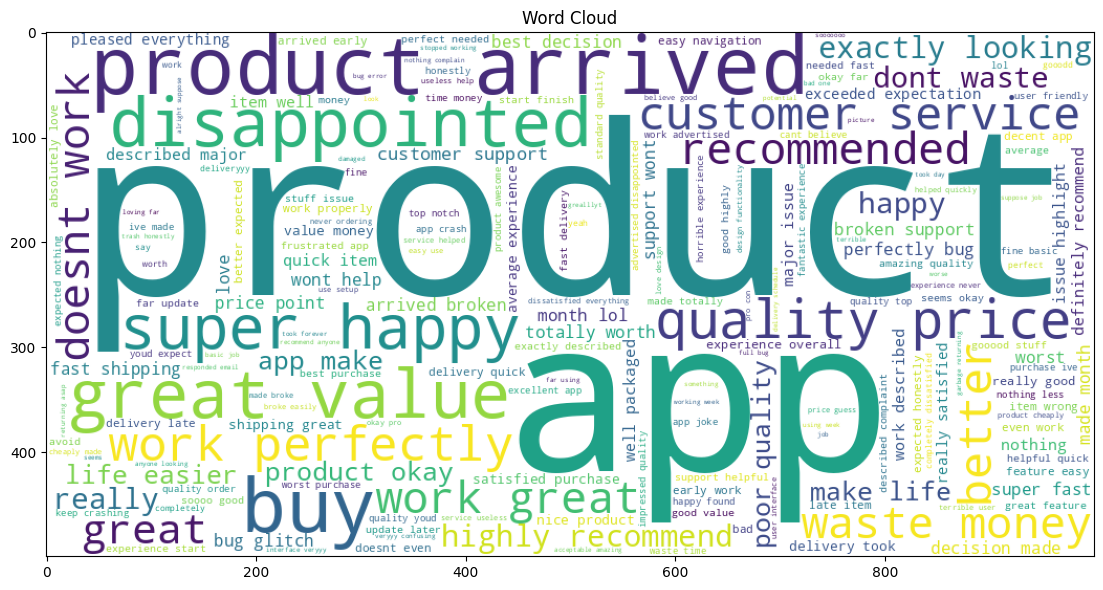

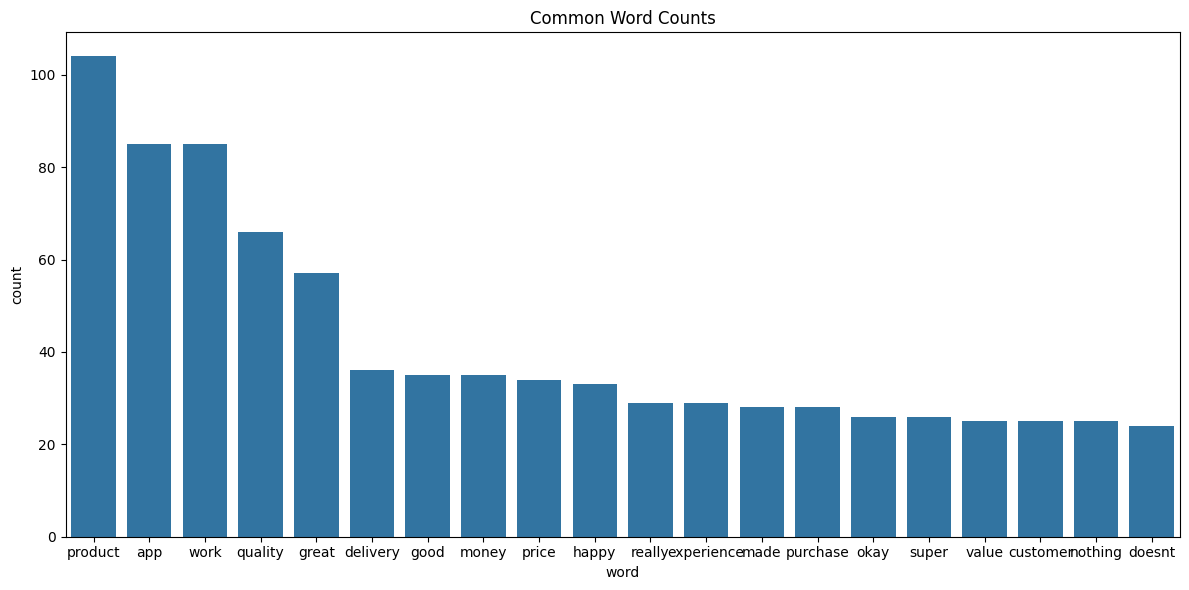

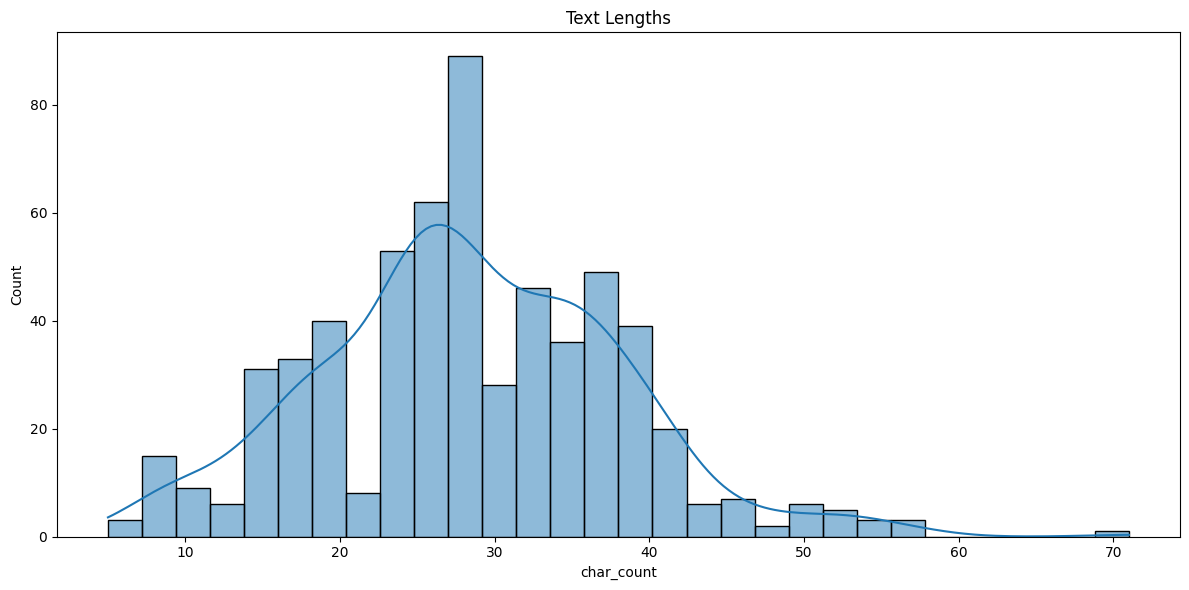

In [191]:
text = " ".join(dataset["cleaned_text"])
wc = WordCloud(width=1000, height = 500, background_color = "white", max_words = 200).generate(text)


plt.figure(figsize=(12,6))
plt.title("Word Cloud")
plt.imshow(wc)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
plt.title("Common Word Counts")
sns.barplot(x="word", y="count", data=common_dataframe.head(20))
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
plt.title("Text Lengths")
sns.histplot(dataset["char_count"], bins=30, kde=True)
plt.tight_layout()
plt.show()

Word Cloud:Shows that product is the m,ost common word which is given as it is a customer dataset and it shows that the positive words are more common and in more variety than negative reviews.

Barplot: Shows the common word counts but provides more information as compared to the word cloud

Histogram: Shows that the lengths of texts are almost a normal distribution which means that the dataset is natural in lengths

In [192]:
bow_vectorizer = CountVectorizer(max_features=20000)
bow = bow_vectorizer.fit_transform(dataset["cleaned_text"])

tfidf_vectorizer = TfidfVectorizer(max_features=20000)
tfidf = tfidf_vectorizer.fit_transform(dataset["cleaned_text"])

print("Bag of Words Shape: ", bow.shape)
print("TF-IDF Shape: ", tfidf.shape)


Bag of Words Shape:  (600, 248)
TF-IDF Shape:  (600, 248)


We are using TFIDF instead of bag of words as bag of words is primitive and doesnt provide much conytext or interdocument frequencies of data.

Logistic Regression Classification Report:
               precision    recall  f1-score   support

    negative       0.87      0.95      0.91        42
     neutral       1.00      0.75      0.86        24
    positive       0.96      1.00      0.98        54

    accuracy                           0.93       120
   macro avg       0.94      0.90      0.92       120
weighted avg       0.94      0.93      0.93       120



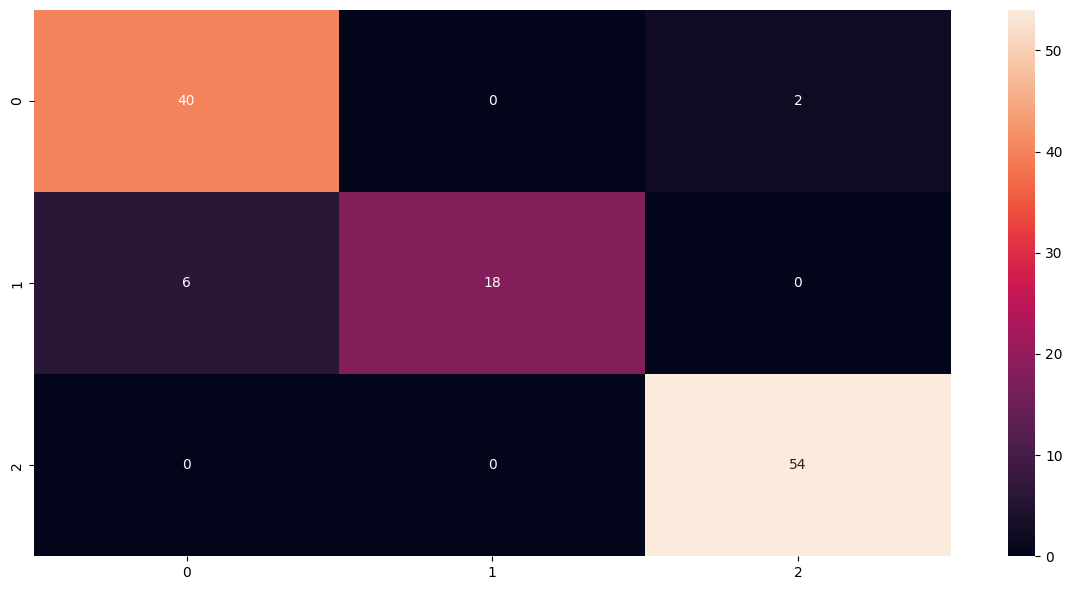

SVM Classification Report:
               precision    recall  f1-score   support

    negative       1.00      1.00      1.00        42
     neutral       1.00      1.00      1.00        24
    positive       1.00      1.00      1.00        54

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



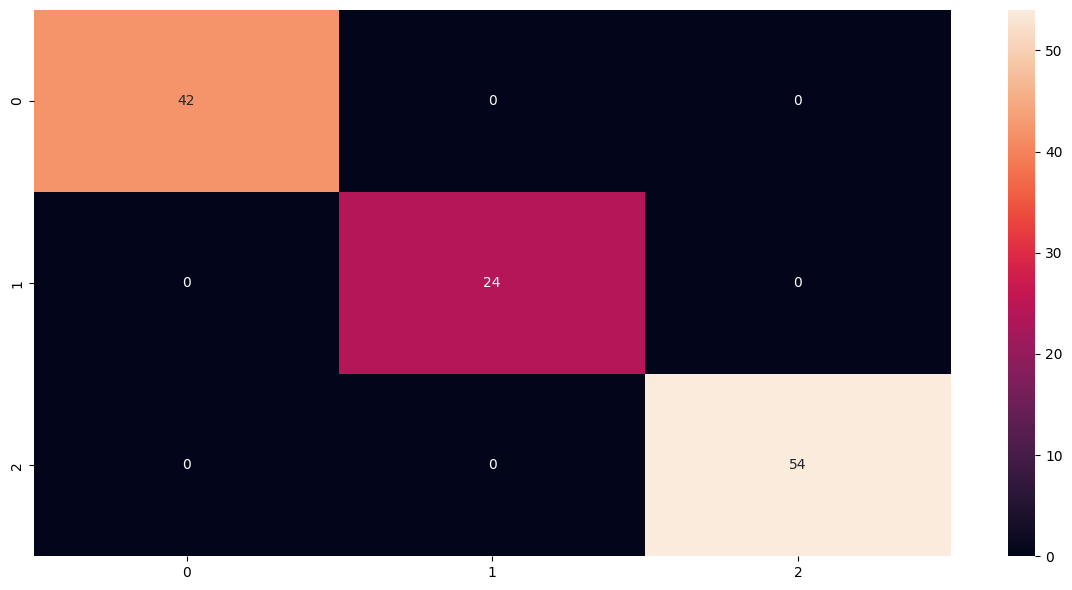

In [193]:
y = dataset["sentiment"]

x_train, x_test, y_train, y_test = train_test_split(tfidf, y, test_size = 0.2, random_state=42, stratify=y)

def evaluate_model(x_test, y_test, model, name="model"):
    result = model.predict(x_test)
    print(f"{name} Classification Report:\n", classification_report(y_test, result))
    plt.figure(figsize=(12, 6))
    sns.heatmap(confusion_matrix(y_test, result), annot=True)
    plt.tight_layout()
    plt.show()


logistic = LogisticRegression(max_iter=1000)
l_model = logistic.fit(x_train, y_train)
evaluate_model(x_test, y_test, l_model, name="Logistic Regression")


support = SVC()
s_model = support.fit(x_train, y_train)
evaluate_model(x_test, y_test, s_model, name="SVM")



I am using SVM at it has perfect scores on even unseen data

In [194]:
class TextCleaner(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return pd.Series(X).apply(clean_text).values


predict_pipeline = Pipeline([
    ('cleaner', TextCleaner()),
    ('vectorizer', tfidf_vectorizer),
    ('model', s_model)
])

def predict_sentiment(texts):
    preds = predict_pipeline.predict(texts if isinstance(texts, (list, pd.Series)) else [texts])
    return preds

testing the model live by providing it sentence to check its sentiment

In [195]:

n = int(input("How many sentences do you want to test? "))

test_sentences = []
for i in range(n):
    sentence = input(f"Enter sentence {i+1}: ")
    test_sentences.append(sentence)

predictions = predict_sentiment(test_sentences)

for s, p in zip(test_sentences, predictions):
    print(f"Text: {s}\nPredicted Sentiment: {p}\n")

How many sentences do you want to test? 1
Enter sentence 1: I am a good boy
Text: I am a good boy
Predicted Sentiment: positive



Dumping all the models and preprocessors to be used on other data

In [196]:
import joblib

joblib.dump(l_model, "l_model.pkl")
joblib.dump(s_model, "s_model.pkl")

joblib.dump(tfidf_vectorizer, "vectorizer.pkl")

joblib.dump(TextCleaner(), "cleaner.pkl")

print("Exported models and vectorizers")


Exported models and vectorizers


PART 2 UNSUPERVISED LEARNING

In [197]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
import seaborn as sns

Reading the dataset into a csv and displaying the dataset information

In [198]:
df = pd.read_csv("customer_behavior_dataset.csv")
print("First 10 rows:")
print(df.head(10))
print("\nShape:", df.shape)
print("\nData types:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("Duplicates: ", df.duplicated().sum())

First 10 rows:
   annual_income  monthly_spend  visit_frequency  avg_purchase_value  \
0       96386.95        5663.84               10              530.42   
1       81068.05        3042.99               10              263.02   
2      103950.55        3495.16                9              245.80   
3       33246.13        1394.61               20               62.21   
4       86164.93        2515.03                8              195.78   
5       64546.79        3486.06               26              156.48   
6       52646.72         747.22                2              328.03   
7       28175.68        1302.82               21               85.45   
8       33602.30        1522.09               25               63.72   
9       70596.96        3686.88               16              125.77   

   online_time_minutes  
0                   50  
1                   47  
2                   20  
3                   72  
4                   44  
5                  121  
6                

In [199]:
features = ["annual_income", "monthly_spend", "visit_frequency", "avg_purchase_value", "online_time_minutes"]
X = df[features]

Scaling the features to give equal importance

In [200]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Trying 2-6 clusters and checking their silhuette scores. 3 clusters provide the best score but logically there are 5 types of spenders and it provides a good enough silhuette as well

In [201]:
k_values = [2, 3, 4, 5, 6]
sil_scores = {}

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    df[f"K{k}_Label"] = labels
    sil = silhouette_score(X_scaled, labels)
    sil_scores[k] = sil
    print(f"K={k}: Silhouette Score = {sil:.4f}")

K=2: Silhouette Score = 0.4080
K=3: Silhouette Score = 0.4799
K=4: Silhouette Score = 0.4393
K=5: Silhouette Score = 0.4769
K=6: Silhouette Score = 0.4397


Displaying the Clusters

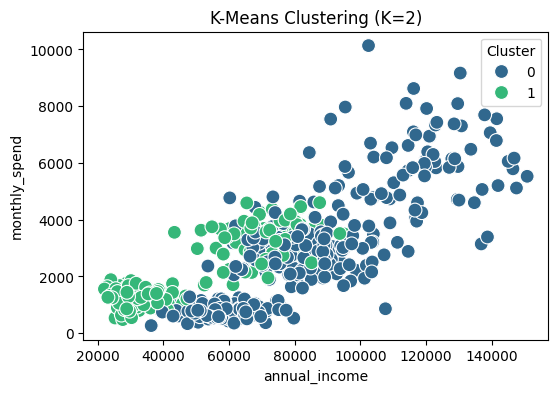

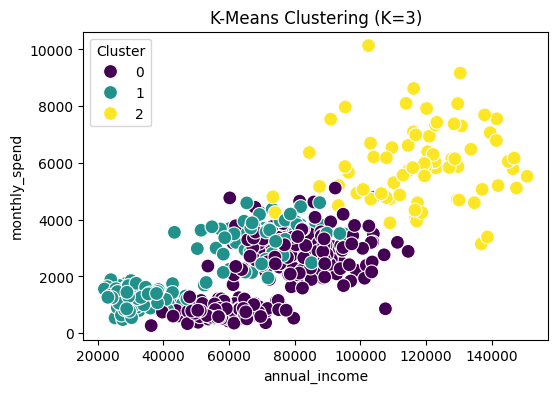

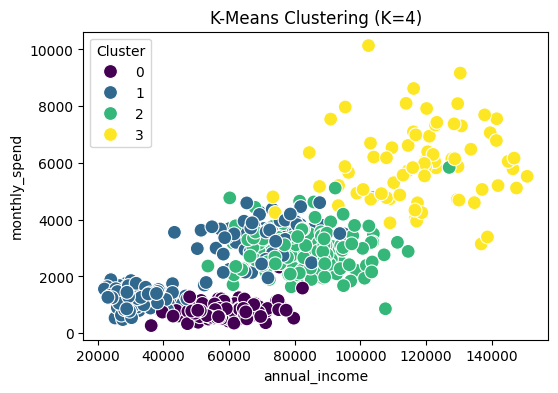

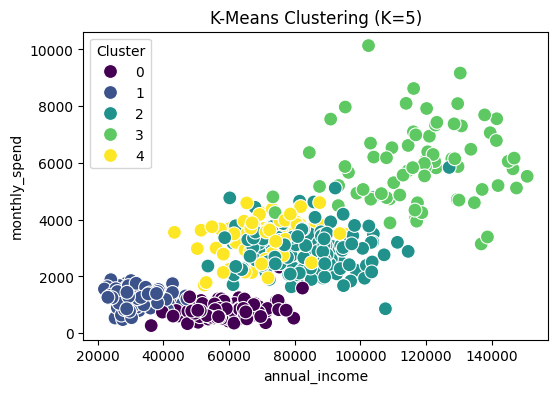

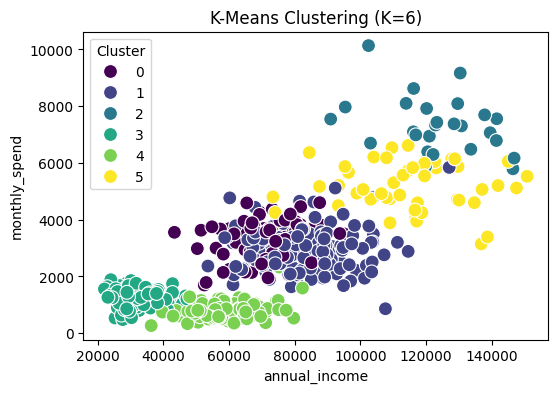

In [202]:
for k in k_values:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x=features[0], y=features[1], hue=f"K{k}_Label", palette='viridis', s=100)
    plt.xlabel(features[0])
    plt.ylabel(features[1])
    plt.title(f"K-Means Clustering (K={k})")
    plt.legend(title='Cluster')
    plt.show()

I am using 5 clusters as they make more sense than 3

In [203]:
km_best = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_best = km_best.fit_predict(X_scaled)
df["BestK_Label"] = labels_best

Displaying the centroids of the cluisters

In [204]:
centers_scaled = km_best.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)
cluster_centers = pd.DataFrame(centers_original, columns=features)
cluster_centers["Cluster"] = cluster_centers.index

print("\nCluster Centers:")
print(cluster_centers)


Cluster Centers:
   annual_income  monthly_spend  visit_frequency  avg_purchase_value  \
0   59104.283774     808.789906         3.207547          214.076321   
1   32795.489904    1238.861346        18.855769           66.800769   
2   84132.292716    2930.851420         8.611111          176.299753   
3  118104.987467    5969.571200        13.000000          412.829867   
4   71286.497123    3317.461096        22.068493          149.777808   

   online_time_minutes  Cluster  
0            15.084906        0  
1            86.307692        1  
2            45.240741        2  
3            37.840000        3  
4           124.068493        4  


Reading the dataset again to refresh

In [205]:
df = pd.read_csv("customer_behavior_dataset.csv")

In [206]:
features = ["annual_income", "monthly_spend", "visit_frequency", "avg_purchase_value", "online_time_minutes"]
X = df[features]

Checking the dendogram of the dataset according to ward linkage to check how many clusters i should make. 4 seems a good choice according to the dendogram

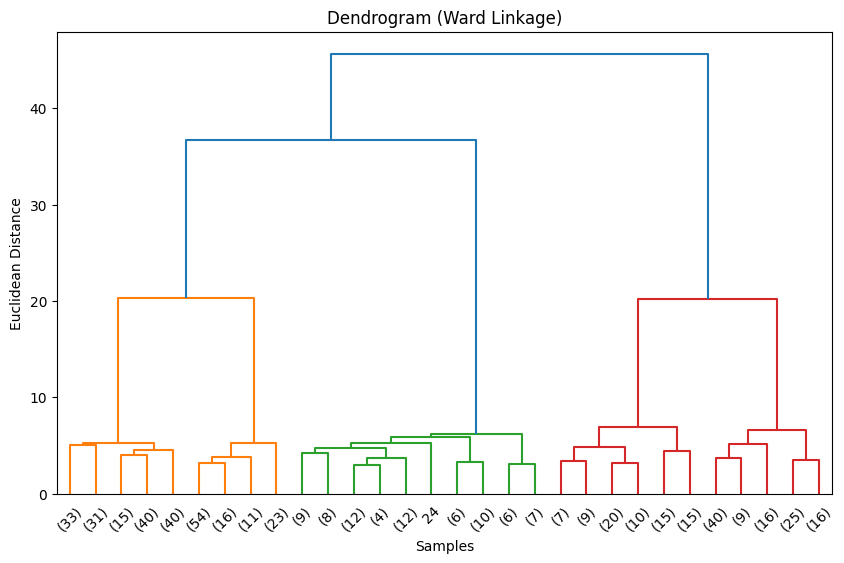

In [207]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 6))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True, truncate_mode='lastp', p=30)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Samples")
plt.ylabel("Euclidean Distance")
plt.show()


In [208]:
n_clusters = 4
hc = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
df["HC_Label"] = hc.fit_predict(X_scaled)
print(f"\nCluster counts (Hierarchical, n_clusters={n_clusters}):")
print(df["HC_Label"].value_counts().sort_index())


Cluster counts (Hierarchical, n_clusters=4):
HC_Label
0    182
1    159
2     75
3    104
Name: count, dtype: int64


In [209]:
df = pd.read_csv("biological_measurement_dataset.csv")
print("First 10 rows:")
print(df.head(10))
print("\nShape:", df.shape)
print("\nData types:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("Duplicates: ", df.duplicated().sum())

First 10 rows:
   feature_1  feature_2  feature_3  feature_4  feature_5
0     172.12     167.58     138.88    12.5911     2553.4
1      94.28      90.25     103.78     9.4936     1997.0
2     108.87      84.62      72.01     7.9364     2031.3
3     214.03     190.72     169.39    13.9106     2622.1
4     165.12     115.74     117.52    10.7847     2342.5
5     191.68     155.92     117.33    11.9977     2868.6
6      88.85      91.67     103.52     9.6441     2075.2
7     113.34     102.44     114.09    10.9593     2227.7
8     186.07     170.90     165.74    14.4978     2365.5
9     169.09     141.92     149.86    13.1139     2616.0

Shape: (150, 5)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   feature_1  150 non-null    float64
 1   feature_2  150 non-null    float64
 2   feature_3  150 non-null    float64
 3   feature_4  150 non-

In [210]:
numeric_cols = ["feature_1", "feature_2", "feature_3", "feature_4", "feature_5"]
X = df[numeric_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Applyoing PCA and getting 2 components instead of 5

In [211]:
pca_2 = PCA(n_components=2)
principal_components_2 = pca_2.fit_transform(X_scaled)
pca_df_2 = pd.DataFrame(principal_components_2, columns=['PC1', 'PC2'])

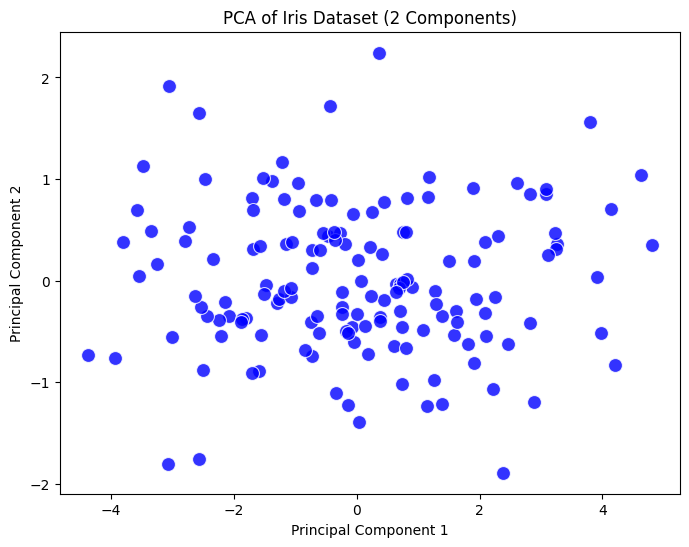

In [212]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df_2, x='PC1', y='PC2', color='blue', s=100, alpha=0.8)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Iris Dataset (2 Components)')
plt.show()

Getting 3 components

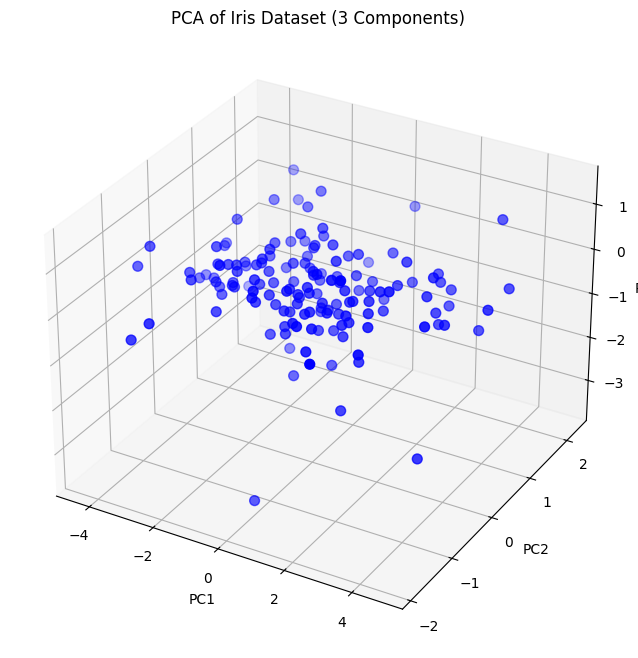

In [213]:
pca_3 = PCA(n_components=3)
principal_components_3 = pca_3.fit_transform(X_scaled)
pca_df_3 = pd.DataFrame(principal_components_3, columns=['PC1', 'PC2', 'PC3'])

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pca_df_3['PC1'], pca_df_3['PC2'], pca_df_3['PC3'], color='blue', s=50)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA of Iris Dataset (3 Components)')
plt.show()

2 components can explain almost 90% of the variance and having 3 can almost explain all of it

In [214]:
print("\nPCA with 2 Components")
explained_var_2 = pca_2.explained_variance_ratio_
for i, var in enumerate(explained_var_2, start=1):
    print(f"PC{i}: {var:.4f}")
print(f"Cumulative variance: {explained_var_2.sum():.4f}")

print("\nPCA with 3 Components")
explained_var_3 = pca_3.explained_variance_ratio_
for i, var in enumerate(explained_var_3, start=1):
    print(f"PC{i}: {var:.4f}")
print(f"Cumulative variance: {explained_var_3.sum():.4f}")


PCA with 2 Components
PC1: 0.7831
PC2: 0.1042
Cumulative variance: 0.8873

PCA with 3 Components
PC1: 0.7831
PC2: 0.1042
PC3: 0.0835
Cumulative variance: 0.9708
